# Sumativa 1 — IBM HR Employee Attrition

**Integrantes:** Hernán Saavedra, Lenin Salas y Rodrigo Gómez.

## Objetivo
Explorar las características personales y laborales asociadas con la salida
de empleados mediante estadística descriptiva, intervalos de confianza
y pruebas de hipótesis.

Se utiliza el dataset original completo. Los datos son sintéticos;
los resultados no representan una empresa real ni permiten establecer causalidad.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Localizar el archivo desde la raíz o desde la carpeta Sumativa1.
raiz = Path.cwd()

if not (raiz / "datos").is_dir():
    raiz = raiz.parent

ruta_datos = raiz / "datos" / "WA_Fn-UseC_-HR-Employee-Attrition.csv"

if not ruta_datos.is_file():
    raise FileNotFoundError(f"No se encontró el dataset en: {ruta_datos}")

# Conservar el original y trabajar sobre una copia.
original = pd.read_csv(ruta_datos)
df = original.copy(deep=True)

sns.set_theme(style="whitegrid")

print(f"Dataset: {df.shape[0]} registros y {df.shape[1]} columnas")
print(f"Python: {sys.version.split()[0]}")
print(f"pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")
print(f"SciPy: {scipy.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print(f"seaborn: {sns.__version__}")

display(df.head())

Dataset: 1470 registros y 35 columnas
Python: 3.13.15
pandas: 3.0.6
NumPy: 2.5.4
SciPy: 1.17.1
Matplotlib: 3.11.2
seaborn: 0.13.2


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 1. Revisión de calidad de los datos

Se revisan tipos de almacenamiento, valores faltantes, filas duplicadas,
columnas constantes y unicidad del identificador. También se comprueba
la presencia de espacios adicionales en las variables de texto.

In [2]:
# Resumen de calidad por variable.
calidad = pd.DataFrame({
    "Tipo en pandas": df.dtypes.astype(str),
    "Faltantes": df.isna().sum(),
    "Valores únicos": df.nunique(dropna=False)
})
calidad.index.name = "Variable"

display(calidad)

# Comprobaciones generales.
constantes = df.columns[df.nunique(dropna=False).eq(1)].tolist()
duplicados = int(df.duplicated().sum())
id_unico = df["EmployeeNumber"].is_unique

print("Total de valores faltantes:", int(df.isna().sum().sum()))
print("Filas duplicadas:", duplicados)
print("Columnas constantes:", constantes)
print("EmployeeNumber es único:", id_unico)

# Detectar espacios al inicio o al final de los textos.
columnas_texto = df.select_dtypes(include=["object", "string"]).columns

espacios = pd.Series({
    columna: int(
        df[columna].dropna().ne(df[columna].dropna().str.strip()).sum()
    )
    for columna in columnas_texto
}, name="Registros con espacios adicionales")

display(espacios.to_frame())

# Revisar categorías y sus frecuencias.
for columna in columnas_texto:
    print(f"\n{columna}")
    display(df[columna].value_counts(dropna=False).to_frame("Frecuencia"))

,Tipo en pandas,Faltantes,Valores únicos
Variable,,,
Age,int64,0,43
Attrition,str,0,2
BusinessTravel,str,0,3
DailyRate,int64,0,886
Department,str,0,3
DistanceFromHome,int64,0,29
Education,int64,0,5
EducationField,str,0,6
EmployeeCount,int64,0,1


Total de valores faltantes: 0
Filas duplicadas: 0
Columnas constantes: ['EmployeeCount', 'Over18', 'StandardHours']
EmployeeNumber es único: True


,Registros con espacios adicionales
Attrition,0
BusinessTravel,0
Department,0
EducationField,0
Gender,0
JobRole,0
MaritalStatus,0
Over18,0
OverTime,0



Attrition


,Frecuencia
Attrition,
No,1233
Yes,237


...

,Frecuencia
MaritalStatus,
Married,673
Single,470
Divorced,327



Over18


,Frecuencia
Over18,
Y,1470



OverTime


,Frecuencia
OverTime,
No,1054
Yes,416


### Validación de consistencia

Se comprueba que las variables cuantitativas seleccionadas no tengan
valores negativos y que las duraciones laborales mantengan relaciones
coherentes. También se revisan los códigos de las escalas ordinales.

Estas comprobaciones detectan posibles inconsistencias internas,
pero no garantizan que todos los registros sean correctos.

In [3]:
validaciones = {
    "Edad no positiva": df["Age"].le(0),
    "Ingreso mensual no positivo": df["MonthlyIncome"].le(0),
    "Distancia negativa": df["DistanceFromHome"].lt(0),
    "Experiencia total negativa": df["TotalWorkingYears"].lt(0),
    "Antigüedad negativa": df["YearsAtCompany"].lt(0),
    "Antigüedad mayor que experiencia total":
        df["YearsAtCompany"].gt(df["TotalWorkingYears"]),
    "Años en cargo mayores que antigüedad":
        df["YearsInCurrentRole"].gt(df["YearsAtCompany"]),
    "Años con jefe mayores que antigüedad":
        df["YearsWithCurrManager"].gt(df["YearsAtCompany"]),
    "Años desde promoción mayores que antigüedad":
        df["YearsSinceLastPromotion"].gt(df["YearsAtCompany"])
}

rangos_ordinales = {
    "Education": range(1, 6),
    "EnvironmentSatisfaction": range(1, 5),
    "JobInvolvement": range(1, 5),
    "JobLevel": range(1, 6),
    "JobSatisfaction": range(1, 5),
    "PerformanceRating": range(1, 5),
    "RelationshipSatisfaction": range(1, 5),
    "StockOptionLevel": range(0, 4),
    "WorkLifeBalance": range(1, 5)
}

for variable, valores_validos in rangos_ordinales.items():
    validaciones[f"{variable}: código fuera de rango"] = (
        ~df[variable].isin(valores_validos)
    )

reporte_consistencia = pd.DataFrame({
    "Comprobación": list(validaciones.keys()),
    "Casos detectados": [
        int(condicion.sum()) for condicion in validaciones.values()
    ]
})

display(reporte_consistencia)

# Mostrar los registros que requieren revisión, si existen.
filas_revisar = pd.DataFrame(validaciones).any(axis=1)

print("Registros que requieren revisión:", int(filas_revisar.sum()))

if filas_revisar.any():
    display(df.loc[filas_revisar])

,Comprobación,Casos detectados
0,Edad no positiva,0
1,Ingreso mensual no positivo,0
2,Distancia negativa,0
3,Experiencia total negativa,0
4,Antigüedad negativa,0
5,Antigüedad mayor que experiencia total,0
6,Años en cargo mayores que antigüedad,0
7,Años con jefe mayores que antigüedad,0
8,Años desde promoción mayores que antigüedad,0
9,Education: código fuera de rango,0


Registros que requieren revisión: 0


### Resultado de la revisión de calidad

El dataset contiene 1.470 registros y 35 columnas, sin valores faltantes
ni filas duplicadas. EmployeeNumber identifica de forma única cada registro.

Las comprobaciones aplicadas no detectaron valores fuera de los rangos
definidos ni inconsistencias en las relaciones entre duraciones laborales.
Por ello, no se realizaron correcciones ni se eliminaron registros.

Para el análisis se excluyeron las tres columnas constantes
(EmployeeCount, Over18 y StandardHours) y el identificador EmployeeNumber.
La base resultante conserva 1.470 registros y 31 variables.

Estos controles verifican aspectos específicos de consistencia interna;
no garantizan la ausencia de otros problemas de calidad.

## 2. Clasificación de variables y selección para el análisis

Se distingue el tipo estadístico de cada variable de su almacenamiento
en pandas. Las escalas de satisfacción, educación y nivel laboral se
consideran ordinales.

Se excluyen del análisis las columnas constantes y EmployeeNumber,
porque identifica registros y no representa una medida del empleado.
El dataset original se conserva intacto.

In [4]:
nominales = [
    "Attrition", "Department", "EducationField",
    "Gender", "JobRole", "MaritalStatus", "OverTime"
]

ordinales = [
    "BusinessTravel", "Education", "EnvironmentSatisfaction",
    "JobInvolvement", "JobLevel", "JobSatisfaction",
    "PerformanceRating", "RelationshipSatisfaction",
    "StockOptionLevel", "WorkLifeBalance"
]

importes = ["DailyRate", "HourlyRate", "MonthlyIncome", "MonthlyRate"]

medidas_enteras = ["DistanceFromHome", "PercentSalaryHike"]

def clasificar_variable(columna):
    if columna == "EmployeeNumber":
        return "Identificador"
    if columna in constantes:
        return "Constante"
    if columna in nominales:
        return "Cualitativa nominal"
    if columna in ordinales:
        return "Cualitativa ordinal"
    if columna in importes:
        return "Cuantitativa tratada como continua"
    if columna in medidas_enteras:
        return "Cuantitativa registrada en enteros"
    return "Cuantitativa discreta: conteo o años enteros"

diccionario = pd.DataFrame({
    "Variable": df.columns,
    "Tipo estadístico": [
        clasificar_variable(columna) for columna in df.columns
    ]
})

display(diccionario)

# Crear la base de análisis sin modificar el original.
excluidas = constantes + ["EmployeeNumber"]
analisis = df.drop(columns=excluidas).copy()

print("Columnas excluidas:", excluidas)
print("Dimensiones de la base de análisis:", analisis.shape)

,Variable,Tipo estadístico
0,Age,Cuantitativa discreta: conteo o años enteros
1,Attrition,Cualitativa nominal
2,BusinessTravel,Cualitativa ordinal
3,DailyRate,Cuantitativa tratada como continua
4,Department,Cualitativa nominal
5,DistanceFromHome,Cuantitativa registrada en enteros
6,Education,Cualitativa ordinal
7,EducationField,Cualitativa nominal
8,EmployeeCount,Constante
9,EmployeeNumber,Identificador


Columnas excluidas: ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']
Dimensiones de la base de análisis: (1470, 31)


## 3. Estadística descriptiva de variables cuantitativas

Se resumen edad, ingreso mensual, distancia al trabajo, antigüedad
y experiencia laboral total mediante medidas de centro, dispersión y forma.

La curtosis se expresa como exceso de curtosis: una distribución normal
tiene valor 0. Los valores positivos indican mayor peso en las colas
respecto de la distribución normal.

In [5]:
variables_numericas = [
    "Age",
    "MonthlyIncome",
    "DistanceFromHome",
    "YearsAtCompany",
    "TotalWorkingYears"
]

datos_numericos = analisis[variables_numericas]

descriptivos = datos_numericos.describe().T.rename(columns={
    "count": "n",
    "mean": "Media",
    "std": "Desviación estándar",
    "min": "Mínimo",
    "25%": "Q1",
    "50%": "Mediana",
    "75%": "Q3",
    "max": "Máximo"
})

descriptivos["RIC"] = descriptivos["Q3"] - descriptivos["Q1"]
descriptivos["Asimetría"] = datos_numericos.skew()
descriptivos["Exceso de curtosis"] = datos_numericos.kurt()

# La tabla con coma decimal se muestra en la celda siguiente.

In [6]:
    # Copia para presentación; los datos numéricos originales se conservan.
tabla_presentacion = descriptivos.copy()

for columna in tabla_presentacion.columns:
    if columna == "n":
        tabla_presentacion[columna] = tabla_presentacion[columna].map(
            lambda valor: f"{valor:.0f}"
        )
    else:
        tabla_presentacion[columna] = tabla_presentacion[columna].map(
            lambda valor: f"{valor:.2f}".replace(".", ",")
        )

display(tabla_presentacion)

,n,Media,Desviación estándar,Mínimo,Q1,Mediana,Q3,Máximo,RIC,Asimetría,Exceso de curtosis
Age,1470,"36,92","9,14","18,00","30,00","36,00","43,00","60,00","13,00","0,41","-0,40"
MonthlyIncome,1470,"6502,93","4707,96","1009,00","2911,00","4919,00","8379,00","19999,00","5468,00","1,37","1,01"
DistanceFromHome,1470,"9,19","8,11","1,00","2,00","7,00","14,00","29,00","12,00","0,96","-0,22"
YearsAtCompany,1470,"7,01","6,13","0,00","3,00","5,00","9,00","40,00","6,00","1,76","3,94"
TotalWorkingYears,1470,"11,28","7,78","0,00","6,00","10,00","15,00","40,00","9,00","1,12","0,92"


### Interpretación

La edad presenta una distribución aproximadamente simétrica: la media (36,92 años) y la mediana (36 años) son casi iguales y la asimetría es baja (0,41). El ingreso mensual, la antigüedad y la experiencia total muestran asimetría positiva, con medias mayores que sus medianas (ingreso: 6.502,93 frente a 4.919; antigüedad: 7,01 frente a 5 años). Esto indica una cola hacia valores altos: la mayoría de los empleados tiene ingresos y antigüedades moderados, y unos pocos registran valores muy superiores.

La antigüedad es la variable con colas más pesadas (exceso de curtosis de 3,94): el 75 % de los empleados lleva 9 años o menos en la empresa, pero el máximo llega a 40. Por esta asimetría, en las comparaciones posteriores se privilegian la mediana y el rango intercuartílico, que son menos sensibles a los valores extremos que la media y la desviación estándar.

## 4. Frecuencias de variables categóricas

Se calculan frecuencias absolutas y porcentajes para la salida de empleados,
las horas extra, el departamento y la satisfacción laboral.

In [7]:
variables_categoricas = [
    "Attrition",
    "OverTime",
    "Department",
    "JobSatisfaction"
]

frecuencias = {}

for variable in variables_categoricas:
    conteos = analisis[variable].value_counts().sort_index()

    tabla = pd.DataFrame({
        "Frecuencia": conteos,
        "Porcentaje": conteos / len(analisis) * 100
    })

    frecuencias[variable] = tabla

    # Formatear únicamente la copia que se muestra.
    presentacion = tabla.copy()
    presentacion["Porcentaje"] = presentacion["Porcentaje"].map(
        lambda valor: f"{valor:.2f}".replace(".", ",")
    )

    print(f"\n{variable}")
    display(presentacion)


Attrition


,Frecuencia,Porcentaje
Attrition,,
No,1233,"83,88"
Yes,237,"16,12"



OverTime


,Frecuencia,Porcentaje
OverTime,,
No,1054,"71,70"
Yes,416,"28,30"



Department


,Frecuencia,Porcentaje
Department,,
Human Resources,63,"4,29"
Research & Development,961,"65,37"
Sales,446,"30,34"



JobSatisfaction


,Frecuencia,Porcentaje
JobSatisfaction,,
1,289,"19,66"
2,280,"19,05"
3,442,"30,07"
4,459,"31,22"


### Interpretación

La variable objetivo está desbalanceada: el 16,12 % de los empleados (237 de 1.470) dejó la empresa y el 83,88 % permanece. Por eso, en el análisis según salida se comparan porcentajes dentro de cada grupo y no conteos absolutos, que estarían dominados por el grupo que permanece.

El 28,30 % de los empleados realiza horas extra. Investigación y Desarrollo concentra el 65,37 % de los registros, mientras que Recursos Humanos representa solo el 4,29 % (63 personas), lo que hace menos estables las estimaciones para ese departamento. En satisfacción laboral, el 61,29 % se ubica en los niveles 3 y 4, aunque cerca de dos de cada diez empleados declara el nivel más bajo.

## 5. Distribución de variables categóricas

Los gráficos muestran el porcentaje de registros en cada categoría.
Estos porcentajes describen la composición del dataset; no corresponden
a porcentajes de salida dentro de cada grupo.

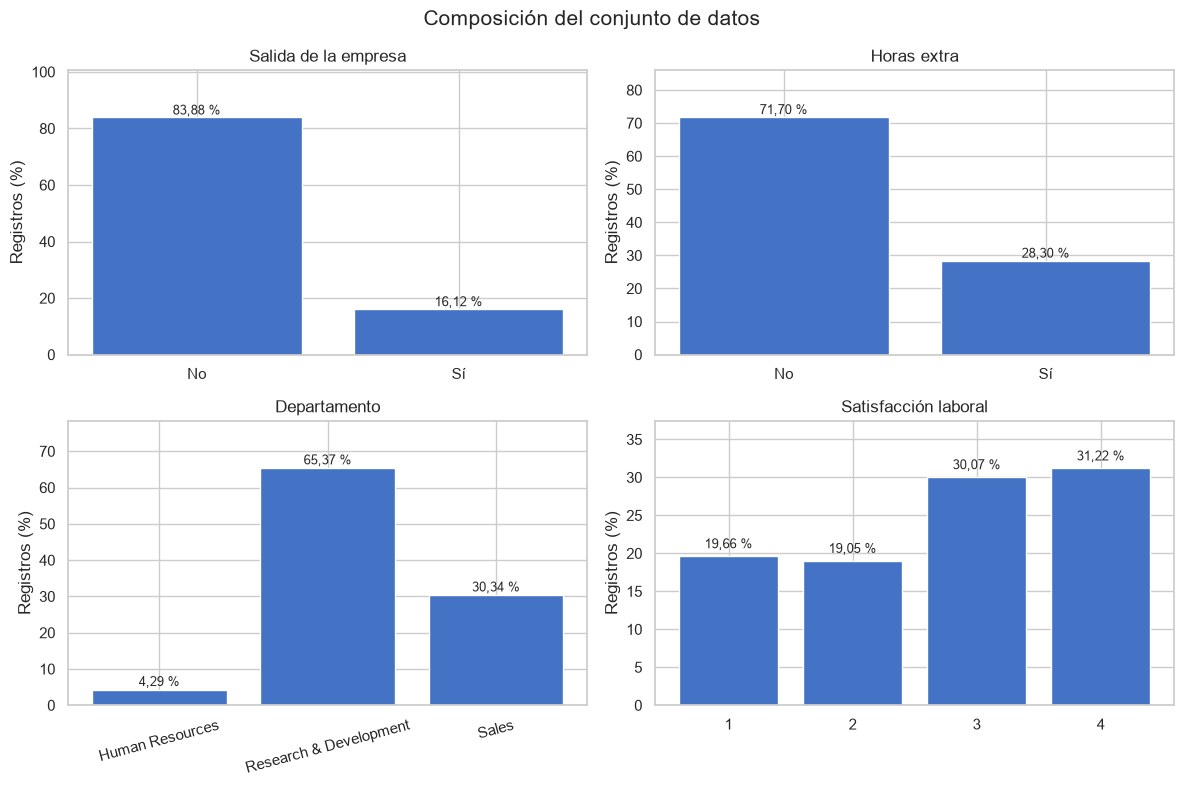

In [8]:
# Carpeta para las figuras de la Sumativa 1.
carpeta_figuras = raiz / "Sumativa1" / "figuras"
carpeta_figuras.mkdir(parents=True, exist_ok=True)

titulos = {
    "Attrition": "Salida de la empresa",
    "OverTime": "Horas extra",
    "Department": "Departamento",
    "JobSatisfaction": "Satisfacción laboral"
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, variable in zip(axes.flat, variables_categoricas):
    tabla = frecuencias[variable]

    etiquetas = [str(categoria) for categoria in tabla.index]

    if variable in ["Attrition", "OverTime"]:
        etiquetas = [
            "Sí" if categoria == "Yes" else "No"
            for categoria in tabla.index
        ]

    barras = ax.bar(
        etiquetas,
        tabla["Porcentaje"],
        color="#4472C4"
    )

    ax.set_title(titulos[variable])
    ax.set_ylabel("Registros (%)")
    ax.set_ylim(0, tabla["Porcentaje"].max() * 1.20)

    for barra, porcentaje in zip(barras, tabla["Porcentaje"]):
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height() + 1,
            f"{porcentaje:.2f} %".replace(".", ","),
            ha="center",
            fontsize=9
        )

    if variable == "Department":
        ax.tick_params(axis="x", labelrotation=15)

fig.suptitle("Composición del conjunto de datos", fontsize=15)
fig.tight_layout()

fig.savefig(
    carpeta_figuras / "figura_1_frecuencias.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretación

La figura 1 resume visualmente la composición del dataset descrita en la sección 4: predomina el grupo que permanece en la empresa, la mayoría no realiza horas extra, Investigación y Desarrollo es el departamento más numeroso y la satisfacción se concentra en los niveles altos. Estos porcentajes describen cómo se distribuyen los registros; las diferencias en la salida dentro de cada grupo se analizan en la sección 8.

## 6. Distribución de variables cuantitativas

Se representan edad, ingreso mensual y antigüedad mediante histogramas
y diagramas de caja. Los puntos fuera de los límites del diagrama de caja
son valores potencialmente atípicos; no se eliminan automáticamente,
porque no implican por sí solos errores de registro.

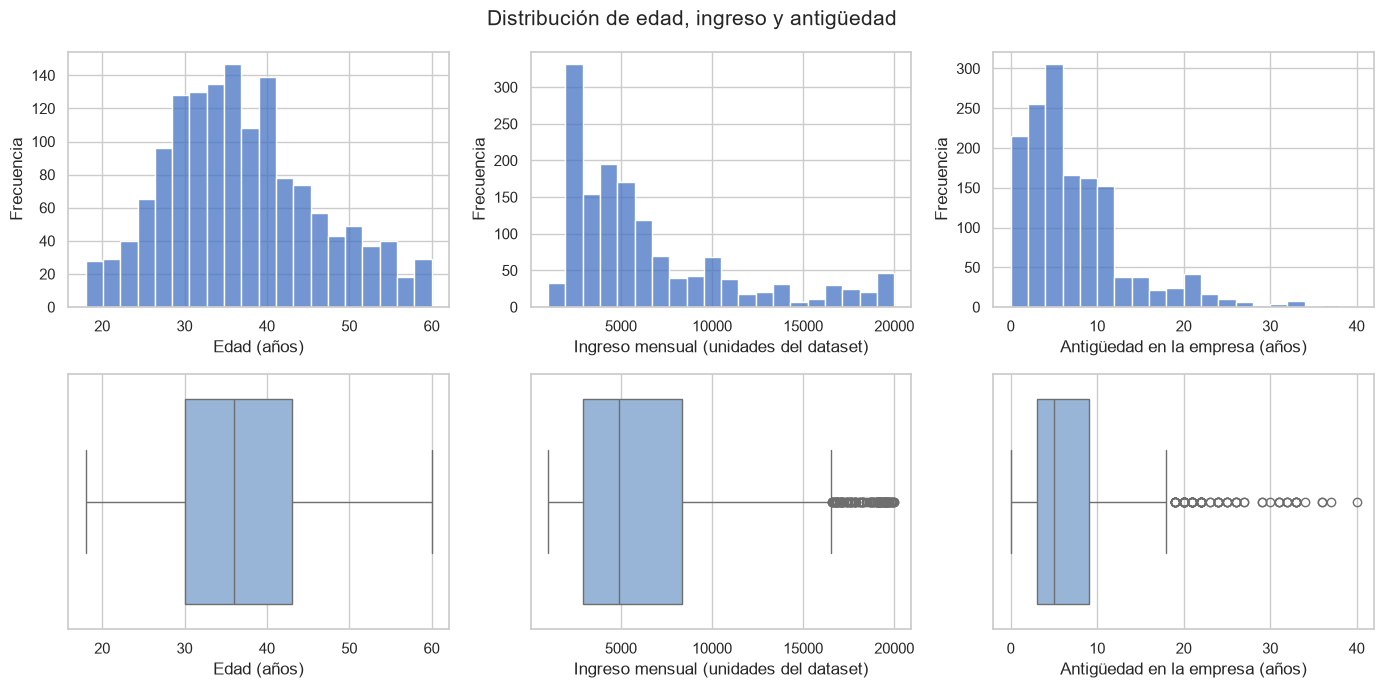

In [9]:
variables_graficos = {
    "Age": "Edad (años)",
    "MonthlyIncome": "Ingreso mensual (unidades del dataset)",
    "YearsAtCompany": "Antigüedad en la empresa (años)"
}

fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for columna, (variable, etiqueta) in enumerate(variables_graficos.items()):
    sns.histplot(
        data=analisis,
        x=variable,
        bins=20,
        color="#4472C4",
        ax=axes[0, columna]
    )
    axes[0, columna].set_xlabel(etiqueta)
    axes[0, columna].set_ylabel("Frecuencia")

    sns.boxplot(
        data=analisis,
        x=variable,
        color="#8DB4E2",
        ax=axes[1, columna]
    )
    axes[1, columna].set_xlabel(etiqueta)

fig.suptitle("Distribución de edad, ingreso y antigüedad", fontsize=15)
fig.tight_layout()

fig.savefig(
    carpeta_figuras / "figura_2_distribuciones.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretación

Los histogramas confirman lo observado en la tabla descriptiva. La edad tiene una forma cercana a la simétrica, concentrada entre los 30 y 43 años, y su diagrama de caja no muestra valores atípicos. El ingreso mensual y la antigüedad presentan una cola larga hacia la derecha: la mayoría de los registros se agrupa en valores bajos y medios, y los diagramas de caja marcan varios valores atípicos altos (ingresos superiores a unos 16.500 y antigüedades mayores a 18 años). Estos valores se conservan, porque son plausibles en una organización (cargos de mayor nivel o trayectorias largas) y no evidencian errores de registro.

## 7. Correlaciones entre variables cuantitativas

Se calcula la correlación de Spearman entre edad, ingreso, distancia,
antigüedad y experiencia laboral total. Se utiliza este método porque
permite explorar relaciones monótonas mediante rangos y resulta menos
sensible a valores extremos que la correlación de Pearson.

Una correlación no demuestra causalidad. Un valor cercano a cero
tampoco descarta relaciones de otro tipo.

,Age,MonthlyIncome,DistanceFromHome,YearsAtCompany,TotalWorkingYears
Age,"1,00","0,47","-0,02","0,25","0,66"
MonthlyIncome,"0,47","1,00","0,00","0,46","0,71"
DistanceFromHome,"-0,02","0,00","1,00","0,01","-0,00"
YearsAtCompany,"0,25","0,46","0,01","1,00","0,59"
TotalWorkingYears,"0,66","0,71","-0,00","0,59","1,00"


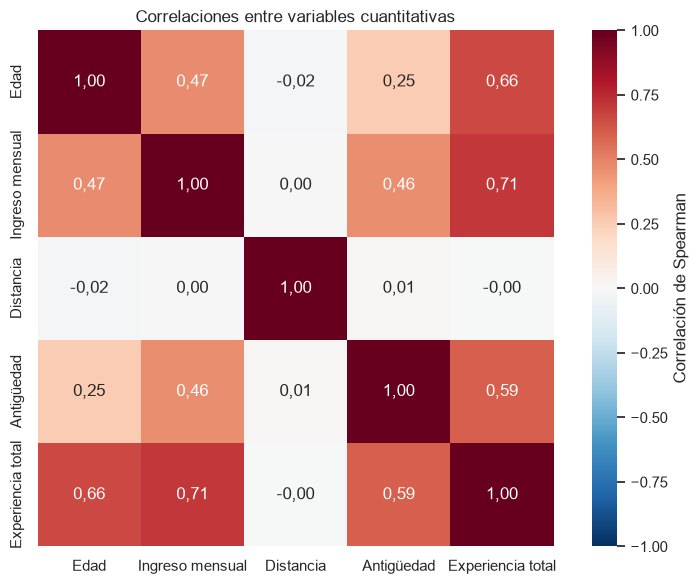

In [10]:
correlaciones = analisis[variables_numericas].corr(method="spearman")

# Tabla con dos decimales y coma decimal.
display(
    correlaciones.apply(
        lambda columna: columna.map(
            lambda valor: f"{valor:.2f}".replace(".", ",")
        )
    )
)

etiquetas = {
    "Age": "Edad",
    "MonthlyIncome": "Ingreso mensual",
    "DistanceFromHome": "Distancia",
    "YearsAtCompany": "Antigüedad",
    "TotalWorkingYears": "Experiencia total"
}

matriz_grafico = correlaciones.rename(
    index=etiquetas,
    columns=etiquetas
)

anotaciones = matriz_grafico.apply(
    lambda columna: columna.map(
        lambda valor: f"{valor:.2f}".replace(".", ",")
    )
)

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    matriz_grafico,
    annot=anotaciones,
    fmt="",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=ax,
    cbar_kws={"label": "Correlación de Spearman"}
)

ax.set_title("Correlaciones entre variables cuantitativas")
fig.tight_layout()

fig.savefig(
    carpeta_figuras / "figura_3_correlaciones.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretación

Las correlaciones más fuertes se dan entre la experiencia laboral total y el ingreso mensual (0,71), la edad (0,66) y la antigüedad (0,59). El ingreso también se asocia de forma moderada con la edad (0,47) y la antigüedad (0,46). Todas son positivas: los empleados con más trayectoria tienden a tener mayores ingresos.

La distancia al trabajo prácticamente no se correlaciona con ninguna de las otras variables (valores entre −0,02 y 0,01). Estas relaciones son relevantes para el análisis según salida: como ingreso, edad, antigüedad y experiencia están vinculados entre sí, una diferencia en una de ellas entre quienes salen y quienes permanecen puede reflejar en parte las demás.

## 8. Análisis bivariado según salida de empleados

In [11]:
# Comparar variables numéricas según salida.
comparacion_salida = (
    analisis.groupby("Attrition")[variables_numericas]
    .agg(["count", "mean", "median", "std"])
)

presentacion = comparacion_salida.copy()
for columna in presentacion.columns:
    if columna[1] == "count":
        presentacion[columna] = presentacion[columna].map(lambda valor: f"{valor:.0f}")
    else:
        presentacion[columna] = presentacion[columna].map(
            lambda valor: f"{valor:.2f}".replace(".", ",")
        )
presentacion = presentacion.rename(
    columns={"count": "n", "mean": "Media", "median": "Mediana", "std": "Desv. estándar"},
    level=1
)
display(presentacion)

# Porcentaje de salida dentro de cada grupo.
tasas_salida = {}

for variable in ["OverTime", "JobSatisfaction", "Department"]:
    tabla = (
        analisis.assign(Salida=analisis["Attrition"].eq("Yes"))
        .groupby(variable)["Salida"]
        .agg(["count", "sum", "mean"])
        .rename(columns={"count": "Total", "sum": "Salidas", "mean": "Porcentaje de salida"})
    )
    tabla["Porcentaje de salida"] *= 100
    tasas_salida[variable] = tabla

    vista = tabla.copy()
    vista["Porcentaje de salida"] = vista["Porcentaje de salida"].map(
        lambda valor: f"{valor:.2f}".replace(".", ",")
    )
    print(variable)
    display(vista)

Age                               MonthlyIncome                    \
              n  Media Mediana Desv. estándar             n    Media  Mediana   
Attrition                                                                       
No         1233  37,56   36,00           8,89          1233  6832,74  5204,00   
Yes         237  33,61   32,00           9,69           237  4787,09  3202,00   

                         DistanceFromHome                                \
          Desv. estándar                n  Media Mediana Desv. estándar   
Attrition                                                                 
No               4818,21             1233   8,92    7,00           8,01   
Yes              3640,21              237  10,63    9,00           8,45   

          YearsAtCompany                              TotalWorkingYears  \
                       n Media Mediana Desv. estándar                 n   
Attrition                                                                 
No                  1233  7,37    6,00           6,10              1233   
Yes                  237  5,13    3,00           5,95               237   

                                         
           Media Mediana Desv. estándar  
Attrition                                
No         11,86   10,00           7,76  
Yes         8,24    7,00           7,17

OverTime


,Total,Salidas,Porcentaje de salida
OverTime,,,
No,1054,110,"10,44"
Yes,416,127,"30,53"


JobSatisfaction


,Total,Salidas,Porcentaje de salida
JobSatisfaction,,,
1,289,66,"22,84"
2,280,46,"16,43"
3,442,73,"16,52"
4,459,52,"11,33"


Department


,Total,Salidas,Porcentaje de salida
Department,,,
Human Resources,63,12,"19,05"
Research & Development,961,133,"13,84"
Sales,446,92,"20,63"


### Interpretación de las tablas

Quienes dejaron la empresa son, en general, más jóvenes, tienen menores ingresos y menos años en la organización que quienes permanecen. La edad mediana es de 32 años frente a 36; el ingreso mensual mediano, de 3.202 frente a 5.204, y la antigüedad mediana, de 3 años frente a 6. La experiencia laboral total sigue el mismo patrón (7 frente a 10 años). Se comparan medianas porque el ingreso y la antigüedad tienen distribuciones asimétricas, y en ellas la media queda desplazada por los valores altos.

La distancia al trabajo es la única variable en que el grupo que sale presenta un valor mayor (mediana de 9 frente a 7 unidades del dataset), aunque la diferencia es moderada y la dispersión es parecida en ambos grupos.

En las variables categóricas, el porcentaje de salida entre quienes hacen horas extra es de 30,53 %, casi tres veces el de quienes no las hacen (10,44 %). Según la satisfacción laboral, la salida baja de 22,84 % en el nivel 1 a 11,33 % en el nivel 4, pero los niveles 2 y 3 son prácticamente iguales (16,43 % y 16,52 %), por lo que la relación no disminuye de forma pareja en cada nivel. Por departamento, Ventas (20,63 %) y Recursos Humanos (19,05 %) superan a Investigación y Desarrollo (13,84 %); el valor de Recursos Humanos debe leerse con cautela porque ese grupo tiene solo 63 empleados.

Estas diferencias son descriptivas. No consideran la relación entre variables (por ejemplo, el ingreso aumenta con la experiencia y la edad) ni permiten concluir que alguna de estas características cause la salida. Si las diferencias son estadísticamente significativas se evalúa en la sección de pruebas de hipótesis.

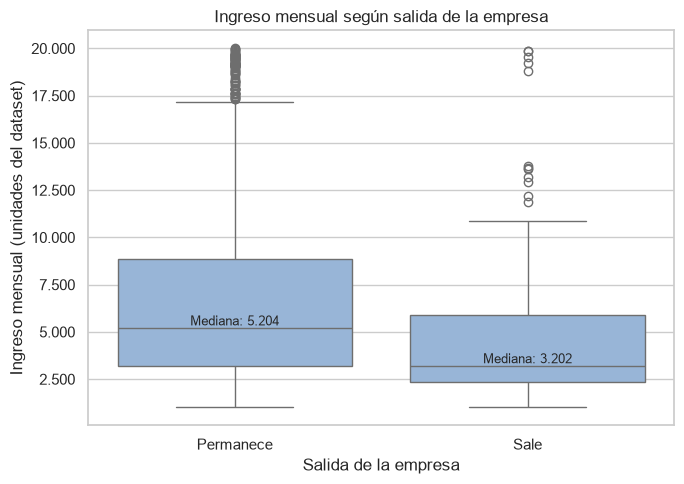

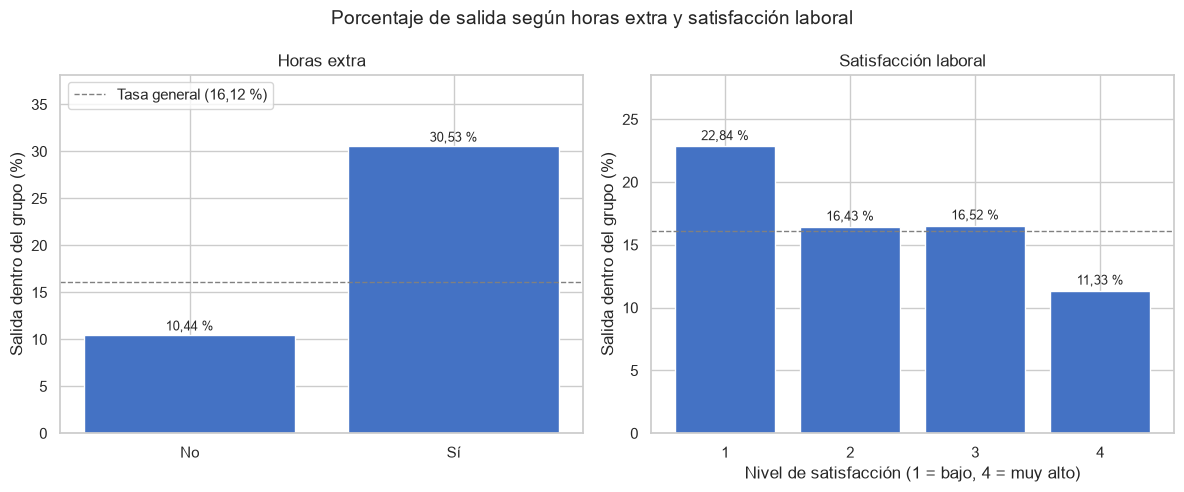

In [12]:
from matplotlib.ticker import FuncFormatter

# Figura 4 · Ingreso mensual según salida
fig, ax = plt.subplots(figsize=(7, 5))

sns.boxplot(
    data=analisis,
    x="Attrition",
    y="MonthlyIncome",
    order=["No", "Yes"],
    color="#8DB4E2",
    ax=ax
)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Permanece", "Sale"])
ax.set_xlabel("Salida de la empresa")
ax.set_ylabel("Ingreso mensual (unidades del dataset)")
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valor, _: f"{valor:,.0f}".replace(",", "."))
)

for posicion, grupo in enumerate(["No", "Yes"]):
    mediana = analisis.loc[analisis["Attrition"].eq(grupo), "MonthlyIncome"].median()
    ax.text(
        posicion, mediana, f"Mediana: {mediana:,.0f}".replace(",", "."),
        ha="center", va="bottom", fontsize=9
    )

ax.set_title("Ingreso mensual según salida de la empresa")
fig.tight_layout()
fig.savefig(carpeta_figuras / "figura_4_ingreso_salida.png", dpi=300, bbox_inches="tight")
plt.show()

# Figura 5 · Porcentaje de salida por horas extra y satisfacción laboral
tasa_general = analisis["Attrition"].eq("Yes").mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, variable, titulo in zip(
    axes,
    ["OverTime", "JobSatisfaction"],
    ["Horas extra", "Satisfacción laboral"]
):
    tabla = tasas_salida[variable]

    if variable == "OverTime":
        etiquetas = ["Sí" if categoria == "Yes" else "No" for categoria in tabla.index]
    else:
        etiquetas = [str(categoria) for categoria in tabla.index]

    barras = ax.bar(etiquetas, tabla["Porcentaje de salida"], color="#4472C4")

    ax.axhline(
        tasa_general, color="gray", linestyle="--", linewidth=1,
        label=f"Tasa general ({tasa_general:.2f} %)".replace(".", ",")
    )

    for barra, porcentaje in zip(barras, tabla["Porcentaje de salida"]):
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height() + 0.5,
            f"{porcentaje:.2f} %".replace(".", ","),
            ha="center", fontsize=9
        )

    ax.set_title(titulo)
    ax.set_ylabel("Salida dentro del grupo (%)")
    ax.set_ylim(0, tabla["Porcentaje de salida"].max() * 1.25)

axes[1].set_xlabel("Nivel de satisfacción (1 = bajo, 4 = muy alto)")
axes[0].legend(loc="upper left")

fig.suptitle("Porcentaje de salida según horas extra y satisfacción laboral", fontsize=14)
fig.tight_layout()
fig.savefig(carpeta_figuras / "figura_5_tasas_salida.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretación de las figuras 4 y 5

En la figura 4, la caja de quienes salen se ubica más abajo y es más angosta que la de quienes permanecen: la mediana del ingreso es de 3.202 frente a 5.204, y la mitad central del grupo que sale se concentra en ingresos bajos. Los ingresos más altos del dataset, sobre 17.500, aparecen casi solo entre quienes permanecen. En ambos grupos hay valores atípicos hacia arriba, coherentes con la asimetría positiva del ingreso descrita en la sección 3; no se eliminan porque no indican errores de registro.

En la figura 5, la línea punteada marca la tasa general de salida (16,12 %). Quienes hacen horas extra quedan muy por sobre ese valor (30,53 %) y quienes no las hacen, por debajo (10,44 %). En satisfacción laboral, solo el nivel 1 supera claramente la tasa general (22,84 %); los niveles 2 y 3 están prácticamente sobre ella y el nivel 4 queda por debajo (11,33 %). La diferencia es más marcada en horas extra que en satisfacción.

Estas figuras describen asociaciones en datos sintéticos. No permiten afirmar que el ingreso bajo, las horas extra o la baja satisfacción causen la salida, y el ingreso puede estar reflejando otras variables relacionadas, como la experiencia o el nivel del cargo.

## 9. Estimación de medias e intervalos de confianza del 95 %

In [13]:
resultados_ic = []

for variable in ["MonthlyIncome", "Age", "YearsAtCompany"]:
    valores = analisis[variable].dropna()
    n = len(valores)
    media = valores.mean()
    error_estandar = stats.sem(valores)

    inferior, superior = stats.t.interval(
        confidence=0.95,
        df=n - 1,
        loc=media,
        scale=error_estandar
    )

    resultados_ic.append({
        "Variable": variable,
        "n": n,
        "Media": media,
        "Error estándar": error_estandar,
        "IC inferior": inferior,
        "IC superior": superior
    })

tabla_ic = pd.DataFrame(resultados_ic)

# Aplicar formato con coma decimal para las columnas numéricas
columnas_numericas = ["Media", "Error estándar", "IC inferior", "IC superior"]

# Diccionario de formato que reemplaza el punto decimal por la coma
format_dict = {
    col: lambda x: f"{x:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".") 
    for col in columnas_numericas
}

tabla_formateada = tabla_ic.style.format(format_dict)
display(tabla_formateada)

,Variable,n,Media,Error estándar,IC inferior,IC superior
0,MonthlyIncome,1470,"6.502,93","122,79","6.262,06","6.743,80"
1,Age,1470,"36,92","0,24","36,46","37,39"
2,YearsAtCompany,1470,"7,01","0,16","6,69","7,32"


Los intervalos de confianza del 95 % para las medias son: ingreso mensual entre 6.262,06 y 6.743,80 unidades del dataset; edad entre 36,46 y 37,39 años; y antigüedad entre 6,69 y 7,32 años.

Se utiliza el intervalo t de Student porque la desviación estándar poblacional es desconocida. El tamaño del conjunto analizado, de 1.470 registros, favorece la aproximación de la distribución de la media, aunque algunas variables presentan asimetría.

Bajo el modelo hipotético de observaciones independientes, el procedimiento produciría intervalos que contienen la media del proceso generador en aproximadamente el 95 % de las repeticiones. Esto no significa que exista una probabilidad del 95 % de que el parámetro esté dentro de cada intervalo ya calculado.

Como los datos son sintéticos y no existe un diseño de muestreo de una empresa real, estos intervalos tienen una finalidad didáctica y no permiten sustentar directamente políticas empresariales.

## 10. Pruebas de hipótesis, Chi-cuadrado: analizar la asociación entre horas extra (OverTime) y salida (Attrition).

Se realizan dos pruebas estadísticas para evaluar relaciones clave con la salida de empleados (`Attrition`):
1. **Prueba de Chi-cuadrado de independencia** para analizar la asociación entre las horas extra (`OverTime`) y la salida de la empresa.
2. **Prueba t de Welch** para comparar el ingreso mensual (`MonthlyIncome`) entre los empleados que salen y los que permanecen, sin asumir varianzas iguales.

In [16]:
# 1. Chi-cuadrado: OverTime vs Attrition
tabla_contingencia = pd.crosstab(analisis['OverTime'], analisis['Attrition'], margins=True)
print("Tabla de contingencia (Frecuencias absolutas):")
display(tabla_contingencia)

# Porcentajes por fila para entender la proporción
tabla_porcentajes = pd.crosstab(analisis['OverTime'], analisis['Attrition'], normalize='index') * 100
print("\nTabla de contingencia (Porcentajes por fila):")
display(tabla_porcentajes.map(lambda x: f"{x:.2f}%".replace(".", ",")))

# Ejecutar la prueba de Chi-cuadrado de Pearson
chi2, p_value, dof, expected = stats.chi2_contingency(pd.crosstab(analisis['OverTime'], analisis['Attrition']))

print("\n--- Resultados Prueba Chi-cuadrado ---")
print(f"Estadístico Chi-cuadrado: {chi2:.4f}")
print(f"Grados de libertad: {dof}")
print(f"P-valor: {p_value:.4e}")

Tabla de contingencia (Frecuencias absolutas):


Attrition,No,Yes,All
OverTime,,,
No,944,110,1054
Yes,289,127,416
All,1233,237,1470



Tabla de contingencia (Porcentajes por fila):


Attrition,No,Yes
OverTime,,
No,"89,56%","10,44%"
Yes,"69,47%","30,53%"



--- Resultados Prueba Chi-cuadrado ---
Estadístico Chi-cuadrado: 87.5643
Grados de libertad: 1
P-valor: 8.1584e-21


## 11. Pruebas de hipótesis, t de Welch: comparar el ingreso mensual (MonthlyIncome) entre quienes salen y quienes permanecen.

In [17]:
# 2. Prueba de Welch: MonthlyIncome según Attrition
ingresos_salen = analisis[analisis['Attrition'] == 'Yes']['MonthlyIncome']
ingresos_permanecen = analisis[analisis['Attrition'] == 'No']['MonthlyIncome']

# Estadísticos descriptivos previos para el ingreso por grupo
resumen_ingresos = pd.DataFrame({
    'Salen (Yes)': [ingresos_salen.count(), ingresos_salen.mean(), ingresos_salen.median(), ingresos_salen.std()],
    'Permanecen (No)': [ingresos_permanecen.count(), ingresos_permanecen.mean(), ingresos_permanecen.median(), ingresos_permanecen.std()]
}, index=['n', 'Media', 'Mediana', 'Desviación estándar'])

print("Resumen de ingresos mensuales según estado de salida:")
display(resumen_ingresos.map(lambda x: f"{x:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")))

# Aplicar la prueba t de Welch (equal_var=False)
t_stat, p_val_welch = stats.ttest_ind(ingresos_salen, ingresos_permanecen, equal_var=False)

print("\n--- Resultados Prueba t de Welch ---")
print(f"Estadístico t: {t_stat:.4f}")
print(f"P-valor: {p_val_welch:.4e}")

Resumen de ingresos mensuales según estado de salida:


,Salen (Yes),Permanecen (No)
n,"237,00","1.233,00"
Media,"4.787,09","6.832,74"
Mediana,"3.202,00","5.204,00"
Desviación estándar,"3.640,21","4.818,21"



--- Resultados Prueba t de Welch ---
Estadístico t: -7.4826
P-valor: 4.4336e-13


### Interpretación de las pruebas

**Chi-cuadrado (`OverTime` vs `Attrition`):** El resultado permite evaluar si existe una dependencia estadísticamente significativa entre realizar horas extra y la decisión o probabilidad de abandonar la organización.
**Prueba de Welch (`MonthlyIncome` vs `Attrition`):** Dado que los ingresos mensuales presentan asimetría, la prueba de Welch es adecuada al no asumir igualdad de varianzas, comparando si las medias de ingreso difieren de manera significativa entre ambos grupos.